In [5]:
import numpy as np
#from numpy.linalg import eigvals, eigvalsh
#from scipy.linalg import eigh
from scipy.sparse.linalg import eigsh,eigs
import matplotlib.pyplot as plt

import Minimal_Model_1D as M

In [6]:
###defining constants##

hbar = 1.055*10**(-34);   #in J-s
ee = 1.602*10**(-19);     #in C
hbar_mev = hbar/ee*1000   # in meV-s
me = 9.11*10**(-31);      #in kg
hbm = hbar**2*1000/2/me/ee/(1e-18) #in meV (nm)**2

Checking convergence for a width of 100 nm

In [7]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 100           # Width in nm
ALPHAT = 400        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.58 + OMEGA   #in between two subbands
MU_SM =  0.58 + OMEGA   #in between two subbands

first subband energy = 0.6101182522944013 
 second subband energy = 1.2202365045888026


In [8]:
K = 4

Tot = 20

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    H = D.H_sys(PHI, so='cu')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)

0
5
10
15


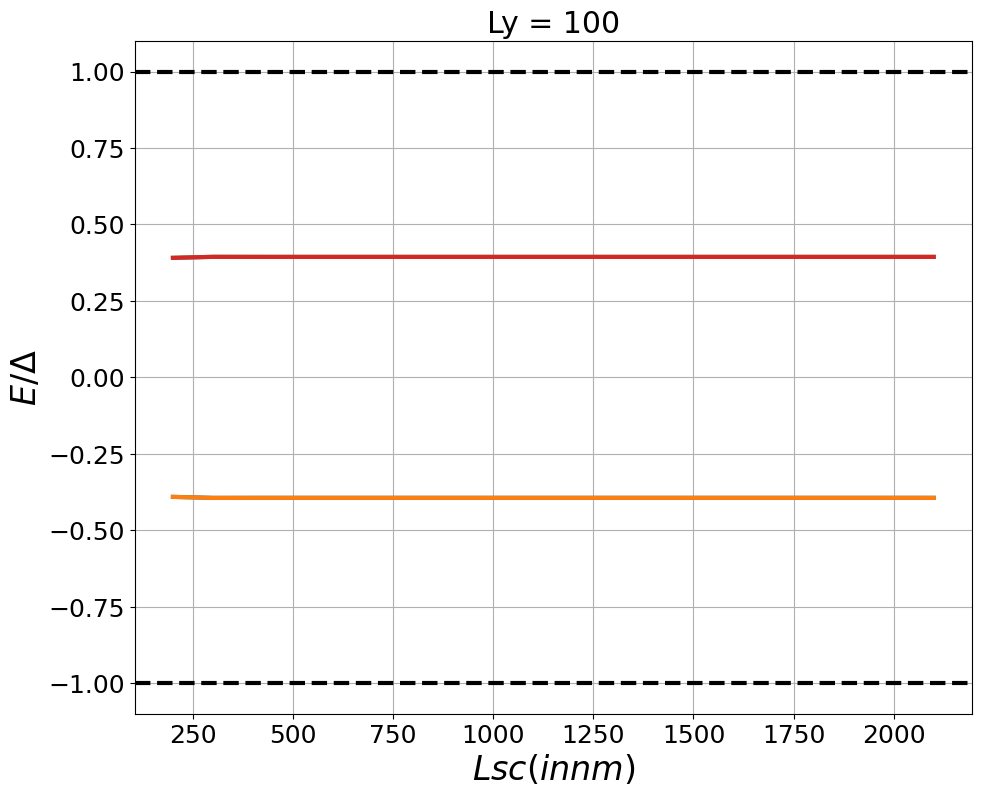

In [10]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [11]:
Ep2 = Ep[:,3]

In [12]:

for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

0.39085013463375057
200 0
0.39415179778491455
300 1
0.3940331024707084
400 2
0.3939971010541183
500 3
0.39399995267870874
600 4
0.39400029139487236
700 5
0.39400038547905
800 6
0.39400047214014816
900 7
0.39400050193013886
1000 8
0.39400050267672926
1100 9
0.39400049629157985
1200 10
0.39400049141358573
1300 11
0.39400048935387666
1400 12
0.39400048900732987
1500 13
0.3940004892448849
1600 14
0.3940004895022002
1700 15
0.39400048963454887
1800 16
0.3940004896702047
1900 17
0.39400048966470386
2000 18


checking convergence for width of 10 nm

first subband energy = 61.011825229440134 
 second subband energy = 122.02365045888027
0
5
10
15
20
25


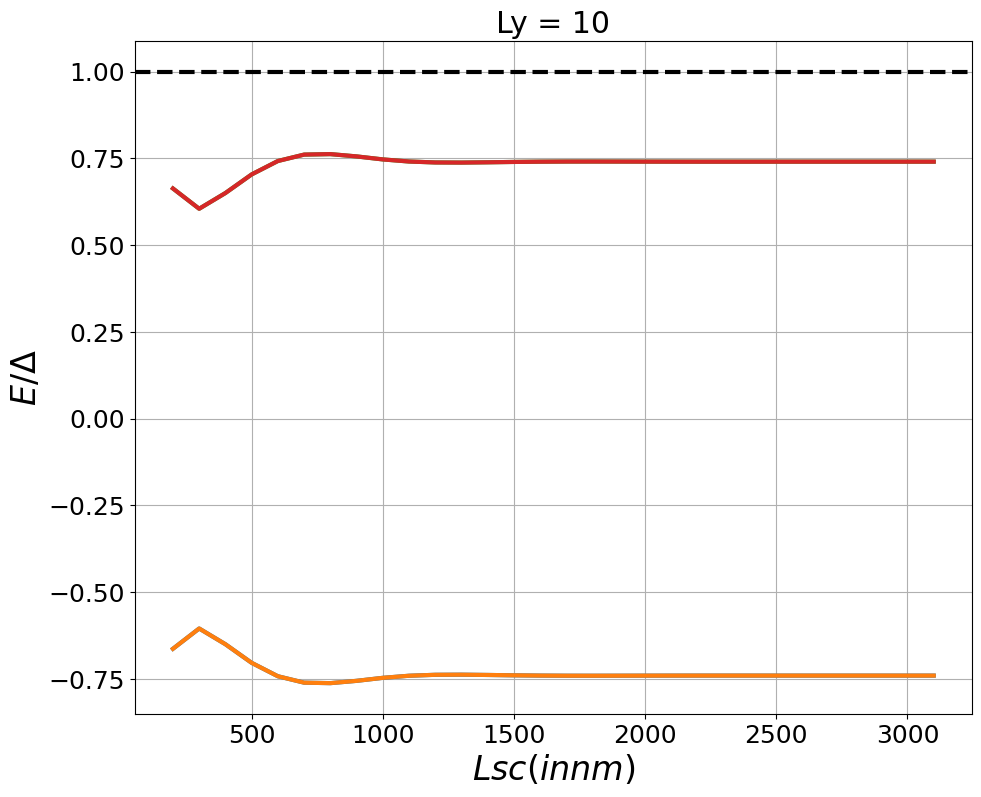

In [13]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
LY = 10            # Width in nm
ALPHAT = 400        # meV-nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge
OMEGA = 2*4*hbm/LY**2/MEFF_SC
PHI = 0.0*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.58 + OMEGA   #in between two subbands
MU_SM =  0.58 + OMEGA   #in between two subbands

K = 4

Tot = 30

Ep = np.empty((Tot,K))

for i in range(Tot):

    NSC = 200 + i*100
    N = 2*NSC + NSM
    D = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    H = D.H_sys(PHI, so='cu')
    E = eigsh(H,k=K,sigma=0, return_eigenvectors=False)
    Ep[i,:] =np.sort(E)
    if i%5==0:
        print(i)

plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))
#f = plt.figure(figsize=(16, 10))
# Define line styles and colors
#line_styles = ['solid', 'solid', 'solid', 'solid', 'solid']
#line_colors = ['blue', 'red', 'blue', 'red', 'blue']

#Ep2 = Ep[:,:]

Lsc = 200 + np.arange(Tot)*100 

plt.plot(Lsc, Ep/DELTA, lw=3)

# Increase the font size of the axes labels and title
plt.xlabel(r'$Lsc(in nm)$', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
#plt.title(r'$E$ vs. $\phi$', fontsize=24)

#plt.grid(True)
plt.grid(True)
#plt.legend(['E1', 'E2', 'E3', 'E4', 'E5'])

# Set x-axis limits to -1 and +1
#plt.xlim(-1, 1)

plt.tight_layout()

# Increase the number of ticks on the x-axis
#plt.xticks(np.linspace(-1, 1, num=10))

# Increase the number of ticks on the y-axis
#plt.yticks(np.linspace(np.min(Ep2), np.max(Ep2), num=10))

# Add dashed lines at +1 and -1 on the y-axis
plt.axhline(1, color='black', linestyle='dashed', lw=3)
#plt.axhline(-1, color='black', linestyle='dashed', lw=3)

# Adjust subplot parameters to remove white space
#plt.subplots_adjust(left=0.08, bottom=0.08, right=0.95, top=0.92)

# Save the plot as an image file
#plt.savefig(os.path.join(folder_loc, 'E_vs_phi_v1.png'))

plt.title('Ly = %i' %LY)

plt.show()




In [14]:
Ep2 = Ep[:,3]


for i in range(Ep2.shape[0]-1):

    if abs(Ep2[i+1]-Ep2[i])/DELTA <=1e-2 :

        print(Ep2[i]/DELTA)
        #print(Ep2[i+1]-Ep2[i])
        #break
        print(200 + i*100 , i)

0.7607612303247254
700 5
0.7621734489255282
800 6
0.7555547755596257
900 7
0.7468982911590428
1000 8
0.7408554101715739
1100 9
0.7381406978543701
1200 10
0.7377951174314819
1300 11
0.7386003249819318
1400 12
0.7396328867131048
1500 13
0.7403976784371845
1600 14
0.7407637339708532
1700 15
0.7408163277896869
1800 16
0.7407091860224643
1900 17
0.7405698361089182
2000 18
0.7404667828273401
2100 19
0.740417230563789
2200 20
0.7404094427730323
2300 21
0.7404230935462818
2400 22
0.7404413656338399
2500 23
0.7404550781471075
2600 24
0.7404617832504446
2700 25
0.7404629291152335
2800 26
0.7404611787090429
2900 27
0.7404587708351905
3000 28


Convergence lengths for cubic SO of 400 meV-nm^3, weak link length of 300 nm and chemical potential of 0.58+OMEGA meV is:
for Ly = 100 nm ~ 200 nm SC on both sides
for Ly = 10 nm ~ 700 nm of SC on both sides

Now looking at the perturbative regime for cubic SO coupling

In [15]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

LY = 100           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.58 + OMEGA   #in between two subbands
MU_SM =  0.58 + OMEGA   #in between two subbands

ALPHAT = np.linspace(10, 1200, 21)

K = 12

Ep_cu = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu
    
    if i%10==0:
        print(i)


first subband energy = 0.6101182522944013 
 second subband energy = 1.2202365045888026
0
10
20


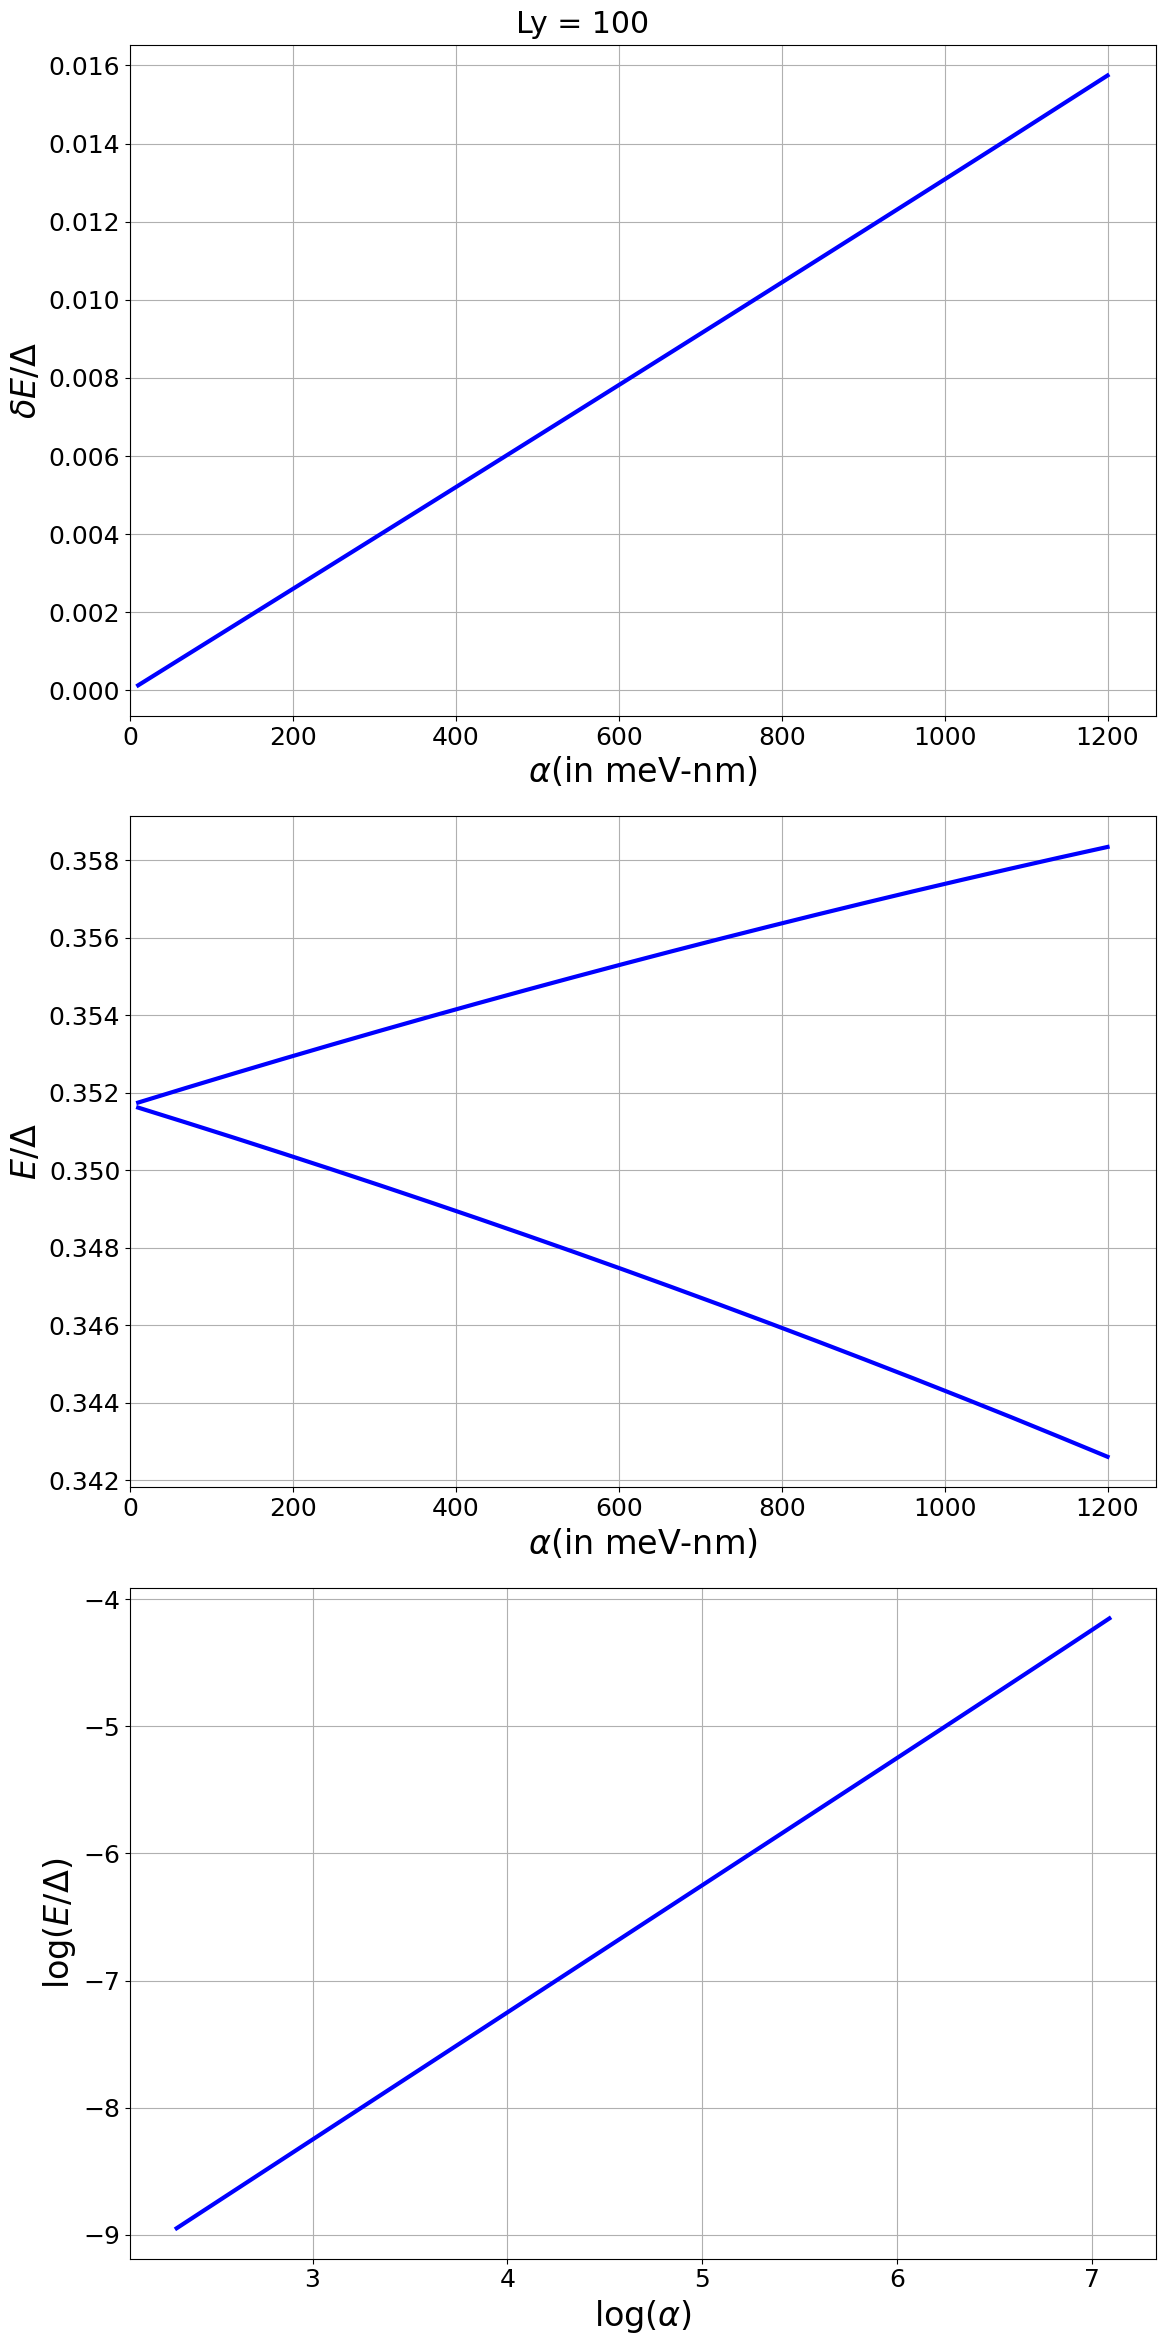

In [16]:
plt.rc('font', size=18)

f = plt.figure(figsize=(12, 24))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

Ep_lower = Ep_cu[:,K//2] 
Ep_upper = Ep_cu[:,K//2+1]


plt.subplot(3,1,1)
plt.plot((ALPHAT), (Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$\delta E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)


plt.subplot(3,1,2)
plt.plot((ALPHAT), (Ep_lower/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.plot((ALPHAT), (Ep_upper/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(3,1,3)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
#plt.xlim(left=0)
plt.grid(True)

plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [17]:
NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

LY = 10           # Width in nm
OMEGA = 2*4*hbm/LY**2/MEFF_SC

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 
#EPSI = 0 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

MU_SC =  0.58 + OMEGA   #in between two subbands
MU_SM =  0.58 + OMEGA   #in between two subbands

ALPHAT = np.linspace(10, 1200, 21)

K = 8

Ep_cu = np.empty((ALPHAT.shape[0],K))
#Kappa = np.empty((ALPHAT.shape[0],1) )

for i in range(ALPHAT.shape[0]):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGA, ALPHAT[i], DELTA, MEFF_SC, MEFF_SM, MU_SC, MU_SM)
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu
    
    if i%10==0:
        print(i)


0
10
20


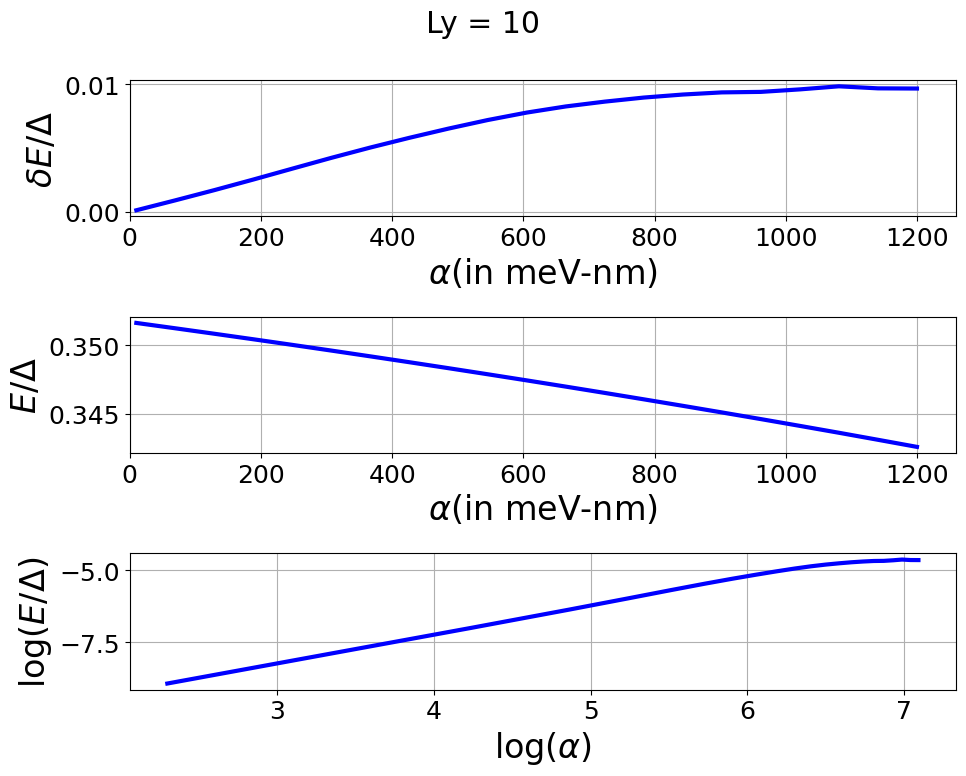

In [18]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

Ep = Ep_cu[:,K//2]

plt.subplot(3,1,1)
plt.plot((ALPHAT), (Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$\delta E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)


plt.subplot(3,1,2)
plt.plot((ALPHAT), (Ep_lower/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'$\alpha$(in meV-nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)
plt.grid(True)
plt.xlim(left=0)

plt.subplot(3,1,3)
plt.plot(np.log(ALPHAT), np.log(Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')
plt.xlabel(r'log($\alpha$)', fontsize=24)
plt.ylabel(r'log($E/\Delta$)', fontsize=24)
#plt.xlim(left=0)
plt.grid(True)


plt.suptitle('Ly = %i' %LY)

plt.tight_layout()

plt.show()

In [19]:
np.exp(6)

403.4287934927351

In [20]:
### Plotting spin splitting while varying width for different chemical potential ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

NSC = 1000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm

LY = np.linspace(10, 200, 51)
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU_SM = 0.58 + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = 0.58 + OMEGA

K = 8

Ep_cu = np.empty((LY.shape[0],K))
#Kappa = np.empty((LY.shape[0],1) )

for i in range(LY.shape[0]):

    Fcu = M.oneD_Minimal_Model(N,NSM, NSC,MY,AX ,OMEGA[i], ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)


0
10
20
30
40
50


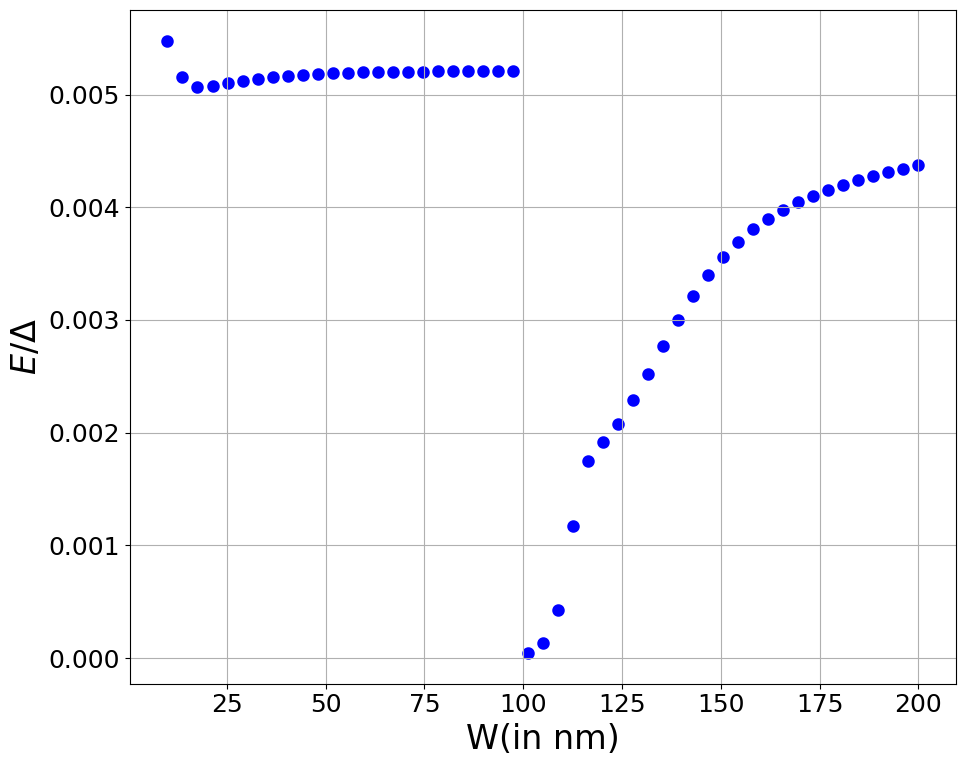

In [21]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

Please note: the model considers two suubands only, hence answers upto W=140 nm only are to be considered 

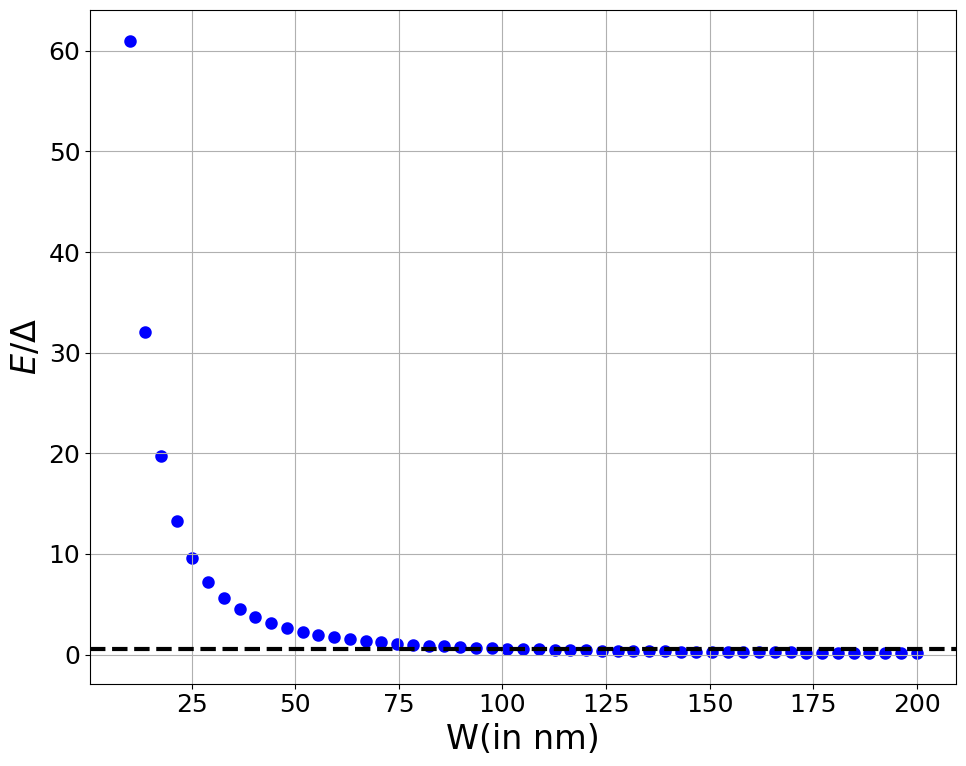

In [27]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY, OMEGA, lw=3 ,linestyle ='-' , color='blue')
plt.axhline(0.58, color='black', linestyle='dashed', lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

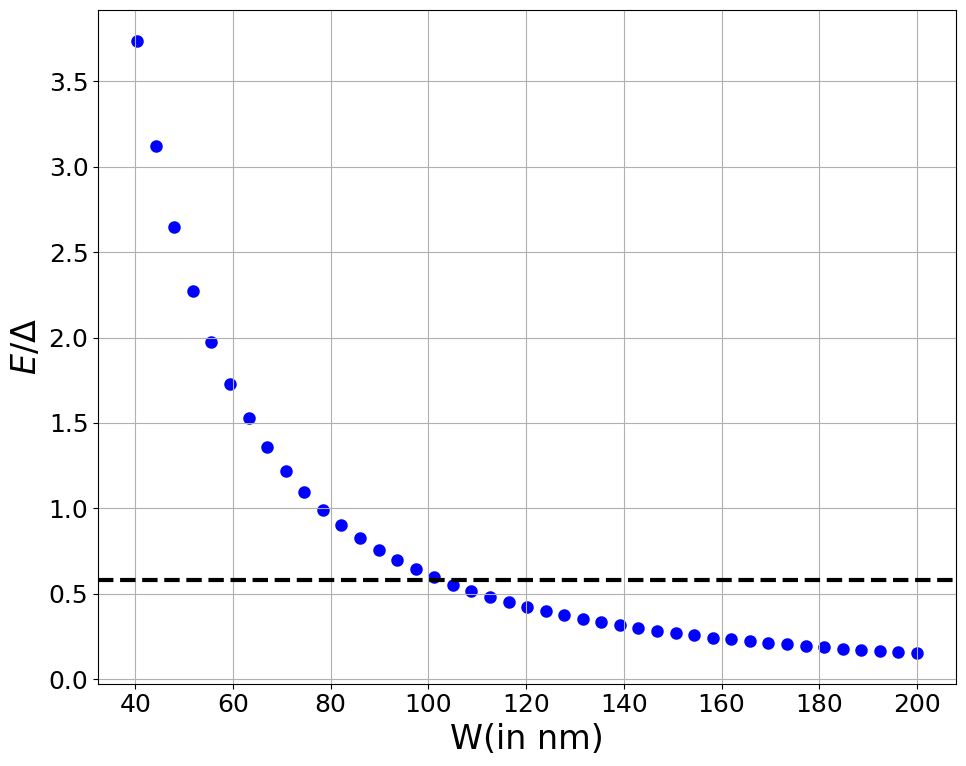

In [28]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY[8:], OMEGA[8:], lw=3 ,linestyle ='-' , color='blue')
plt.axhline(0.58, color='black', linestyle='dashed', lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

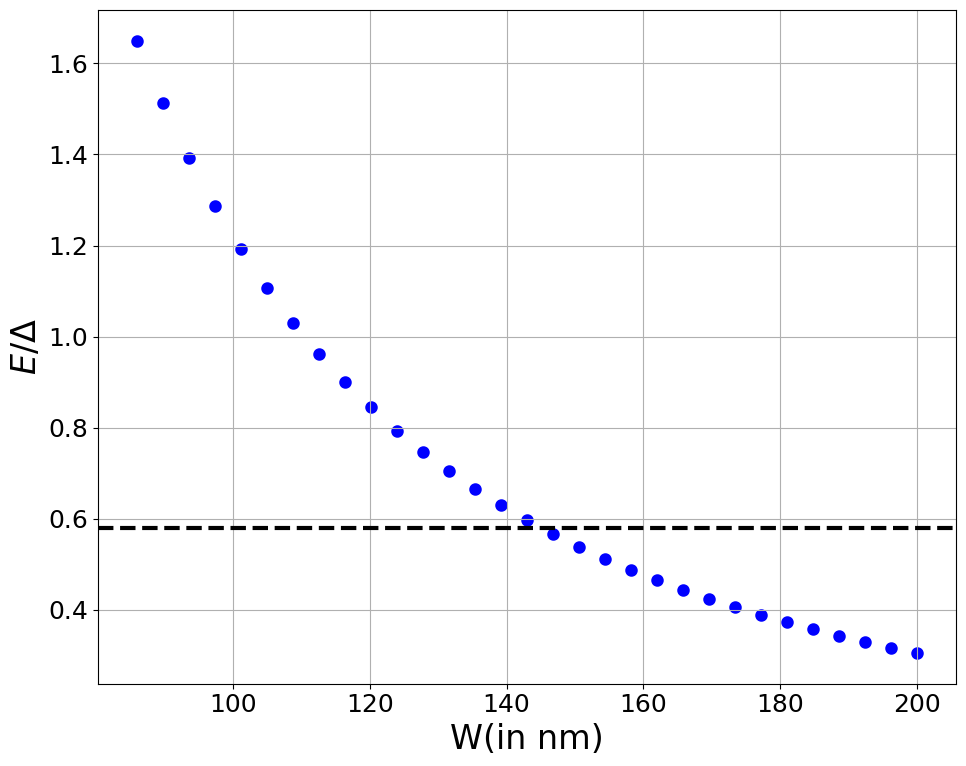

In [29]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

#Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(LY[20:], 2*OMEGA[20:], lw=3 ,linestyle ='-' , color='blue')
plt.axhline(0.58, color='black', linestyle='dashed', lw=3)

plt.xlabel(r'W(in nm)', fontsize=24)
plt.ylabel(r'$E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

## Spin splitting vs $\mu$

In [30]:
#LY = np.linspace(10, 200, 51)
LY = 50
OMEGA = 2*4*hbm/LY**2/MEFF_SC
print(OMEGA)

2.4404730091776052


### Plotting spin splitting while varying chemical potential for a constant width

In [32]:
### Plotting spin splitting while varying width for different chemical potential ###

NSM = 300          # in nm
MY = 2             # no of subbands
AX = 1             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.05     # proximitized Ge 
MEFF_SM = 0.05     # Ge

NSC = 2000
N = 2*NSC + NSM
PHI = 0.5*np.pi 

#print('first subband energy =' , OMEGA , '\n', 'second subband energy =' , 2*OMEGA)

ALPHAT = 400  #meV-nm^3 # 20 is within perturbative regime for widths atleast up to 100 nm

#LY = np.linspace(10, 200, 51)
LY = 50
OMEGA = 2*4*hbm/LY**2/MEFF_SC

MU = np.linspace(0.001, 0.999*OMEGA, 21)

MU_SM = MU + OMEGA        ## As per Andreev Aprroximation chemical pot >> superconducting gap 
MU_SC = MU + OMEGA

K = 8

Ep_cu = np.empty((MU.shape[0],K))
#Kappa = np.empty((LY.shape[0],1) )

for i in range(MU.shape[0]):

    Fcu = M.oneD_Minimal_Model(N, NSM, NSC, MY, AX, OMEGA, ALPHAT, DELTA, MEFF_SC, MEFF_SM, MU_SC[i], MU_SM[i])
    #Kappa[i] = Fli.Ky_pr(1,2).real*ALPHAT/OMEGA[i]
    
    Hcu = Fcu.H_sys(PHI, so = 'cu')
    
    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu[i,:] = Ecu 
    
    if i%10==0:
        print(i)


0
10
20


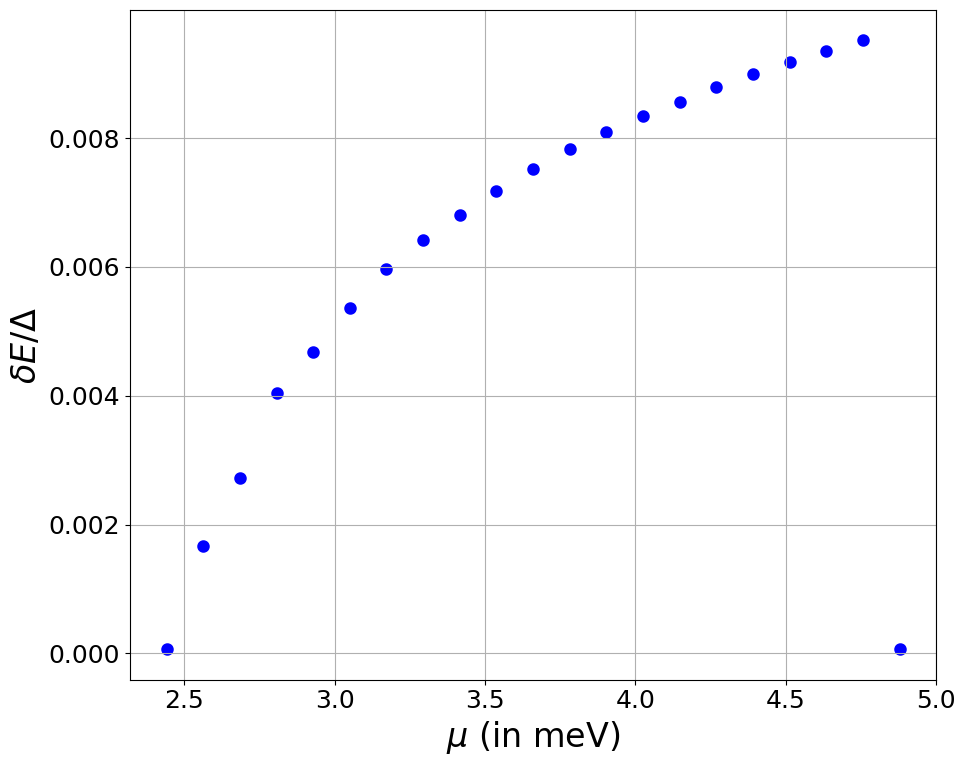

In [34]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(MU+OMEGA, Ep_Split_cu/DELTA, lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'$\mu$ (in meV)', fontsize=24)
plt.ylabel(r'$\delta E/\Delta$', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()

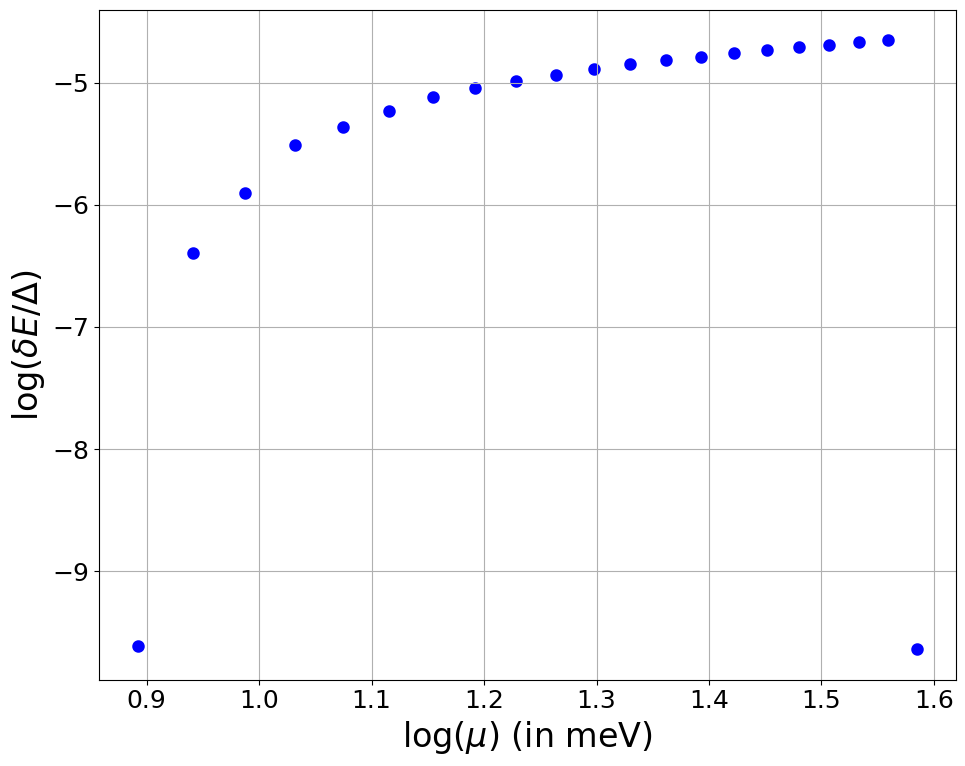

In [35]:
plt.rc('font', size=18)

f = plt.figure(figsize=(10, 8))

Ep_Split_cu = Ep_cu[:,K//2+1] - Ep_cu[:,K//2]

plt.scatter(np.log(MU+OMEGA), np.log(Ep_Split_cu/DELTA), lw=3 ,linestyle ='-' , color='blue')

plt.xlabel(r'log($\mu$) (in meV)', fontsize=24)
plt.ylabel(r'log($\delta E/\Delta$)', fontsize=24)

plt.grid(True)

plt.tight_layout()

plt.show()